In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import config as c
import numpy as np

In [2]:
sns.set_context("notebook")
sns.set_style("whitegrid")
sns.set_theme(

    rc={"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],

        "axes.labelsize": 13,
        "axes.titlesize": 15,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 11,
        "legend.title_fontsize": 12,

        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 1.0})

Let's process already cleaned and fully preprocessed (continous signal processing + windowed signal processing) exams. In exams_processed.csv there are only "ok" recordings, to proceed with in trainings.

## upload metadata & have a first look

In [3]:
filepath = f"{c.META_DIR}/exams_processed.csv"
df = pd.read_csv(filepath, encoding = 'utf-8')
df.head()

,site,patient_id,exam_id,age,age_group,female,pathology
0,S00,P28505,20220512-162946-{3ad3c86b-3d61-440e-81df-b74fd...,36.9,36-45,0,1
1,S00,P28499,20220512-163059-{c7e51449-0539-4208-9962-61bd1...,50.5,46-55,1,1
2,S00,P28497,20220512-162502-{e7d9d501-f72e-4045-afaf-d8827...,45.2,36-45,1,1
3,S00,P28496,20220512-170457-{f141a0b0-1275-435f-9cf1-4ead3...,23.4,16-25,1,0
4,S00,P28496,20220512-163126-{4b9b23b2-ef37-4efb-9d38-c1909...,17.8,16-25,1,1


In [4]:
df.shape

(38542, 7)

The shape is the same as memmap, so it's good.

In [5]:
new_filename_1 = f'{c.META_DIR}/sites_processed.csv'
new_filename_2 = f'{c.META_DIR}/longitudinal_processed.csv'

In [6]:
LABEL_PALETTE = {'0': "#4A90E2", '1': "#E06666"}
SEX_PALETTE = {'0': "#00A878", '1': "#9B51E0"}

bins = [0, 1]
label_labels = ['Norm', 'Pathology']
sex_labels = ['Male', 'Female']

SITE_ORDER = ['S00', 'S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09',
       'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'S19',
       'S21', 'S22', 'S23', 'S24', 'S25', 'S26', 'S28', 'S29']


In [7]:
N_exams_original = df.shape[0]
N_prior = 51135

/tmp/ipykernel_2011697/2834921473.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(x = 'pathology',


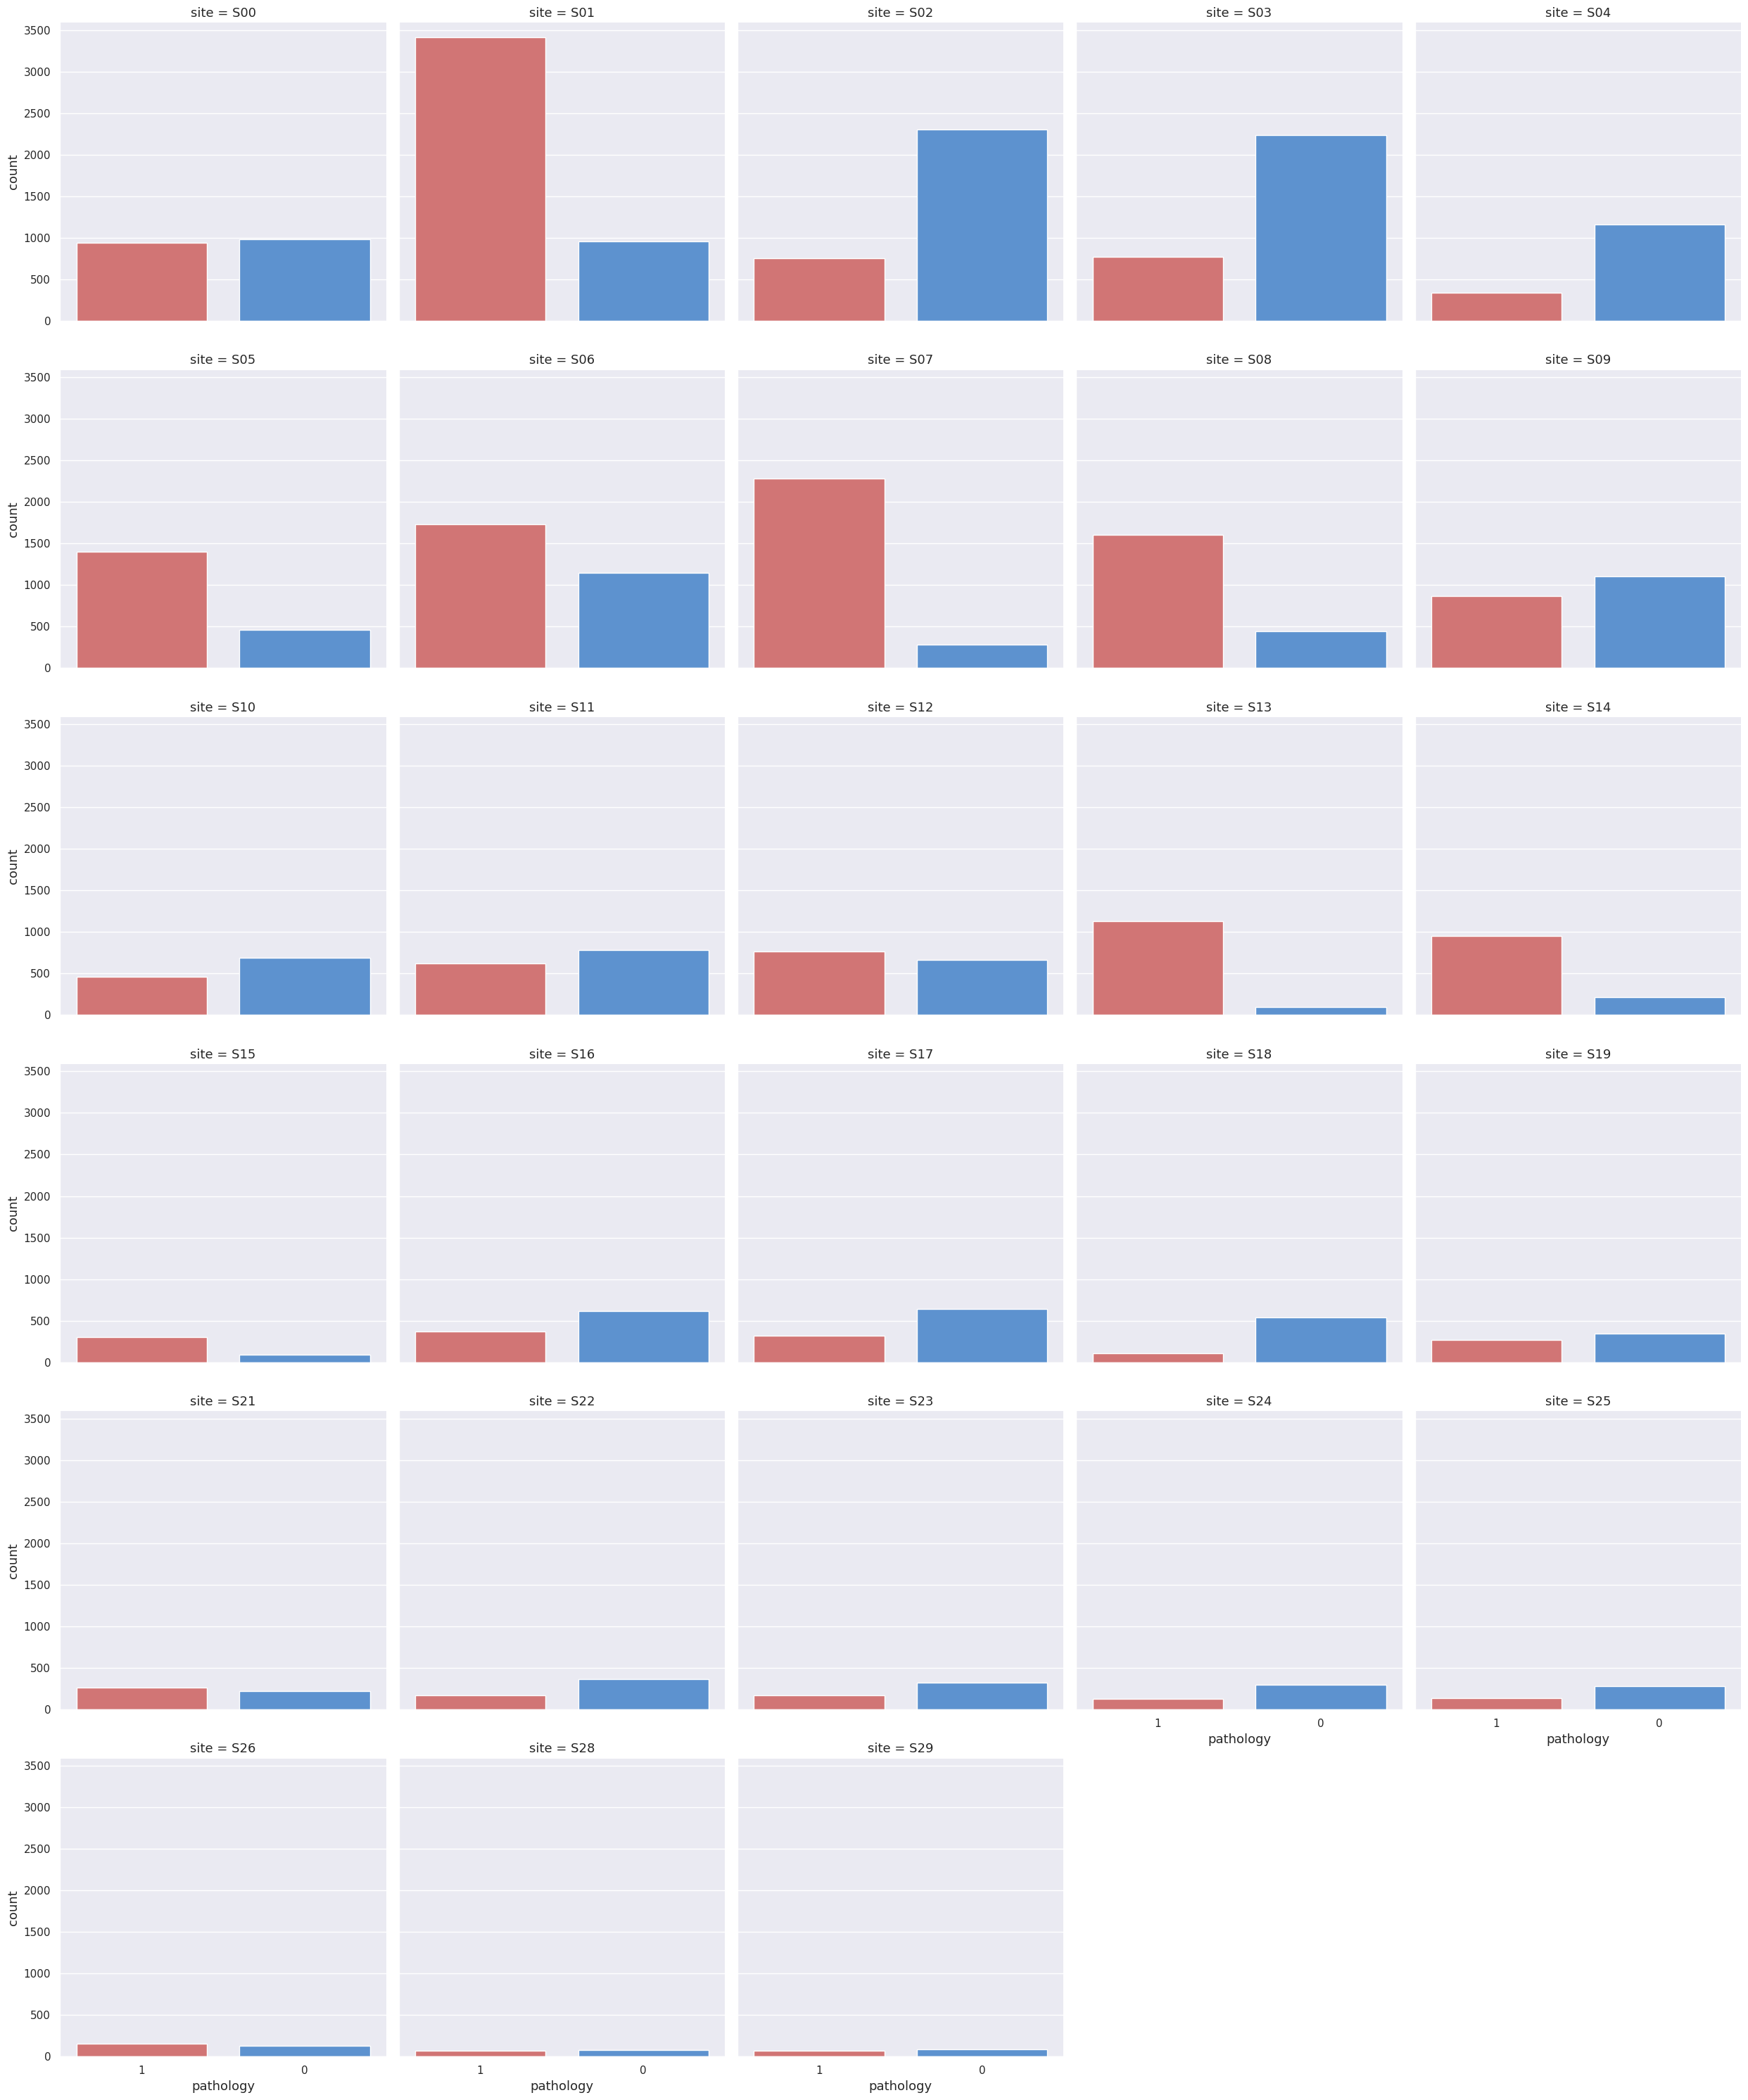

In [8]:
sns.catplot(x = 'pathology',
            data = df,
            col = 'site',
            col_wrap = 5,
            kind = 'count',
            order = [1,0],
            palette = LABEL_PALETTE,
            col_order = SITE_ORDER)

All recordings from S20 & S27 have been removed during DSP.

In [9]:
df.isnull().any()

site          False
patient_id    False
exam_id       False
age           False
age_group     False
female        False
pathology     False
dtype: bool

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38542 entries, 0 to 38541
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   site        38542 non-null  object 
 1   patient_id  38542 non-null  object 
 2   exam_id     38542 non-null  object 
 3   age         38542 non-null  float64
 4   age_group   38542 non-null  object 
 5   female      38542 non-null  int64  
 6   pathology   38542 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 2.1+ MB


In [11]:
print(f"There are {N_exams_original} in the final dataset. Preprocessing-only discarded {N_prior - N_exams_original} exams, which is {np.round((N_prior-N_exams_original)/N_prior, 2)*100}%.")

There are 38542 in the final dataset. Preprocessing-only discarded 12593 exams, which is 25.0%.


## descriptive statistics 

In [12]:
df_structure_global = pd.DataFrame({'Metric': [ '# exams', '# unique patients',
                                                '# longitudinal patients'],
                                    'Value': [  len(df), df['patient_id'].nunique(),
                                                df['patient_id'].value_counts().gt(1).sum()]})
df_structure_global.style.hide(axis='index')

Metric,Value
# exams,38542
# unique patients,31573
# longitudinal patients,3717


In [13]:
label_counts = df['pathology'].value_counts()
target_ratio = label_counts[1] / (label_counts[0] + label_counts[1])
relation = label_counts[1] / label_counts[0]

print("Target count: ", label_counts[1])
print("Target ratio (pathology/all labels):", target_ratio.round(2) * 100, '%') #type:ignore
print("Pathology : norm relation:", relation.round(2)) #type:ignore

Target count:  20963
Target ratio (pathology/all labels): 54.0 %
Pathology : norm relation: 1.19


Target class is overrepresented, but in global perspective it is not a huge imbalance.

In [14]:
sex_count = df['female'].value_counts()
female_ratio = sex_count[1] / (sex_count[0] + sex_count[1])
sex_relation = sex_count[1] / sex_count[0]

print("Female count: ", sex_count[1] )
print("Female ratio (female/all subjects):", female_ratio.round(2)*100, '%') #type:ignore   
print("Female : male relation:", sex_relation.round(1)) #type:ignore

Female count:  20282
Female ratio (female/all subjects): 53.0 %
Female : male relation: 1.1


In [16]:
age_group_counts = df['age_group'].value_counts().sort_index()
AGE_ORDER = []
print('Sorted age group distribution :')
for age_group, count in age_group_counts.sort_values(ascending=False).items():
    print(f"Age group {age_group}: {count} ({(count / len(df) * 100):.2f}%)")  # type: ignore
    AGE_ORDER.append(age_group)

Sorted age group distribution :
Age group 16-25: 9971 (25.87%)
Age group 26-35: 8184 (21.23%)
Age group 36-45: 6986 (18.13%)
Age group 46-55: 6806 (17.66%)
Age group 56-65: 6595 (17.11%)


In [17]:
AGE_ORDER

['16-25', '26-35', '36-45', '46-55', '56-65']

In [18]:
df['age'].describe()

count    38542.000000
mean        38.548218
std         14.714665
min         16.000000
25%         25.500000
50%         37.300000
75%         51.800000
max         65.000000
Name: age, dtype: float64

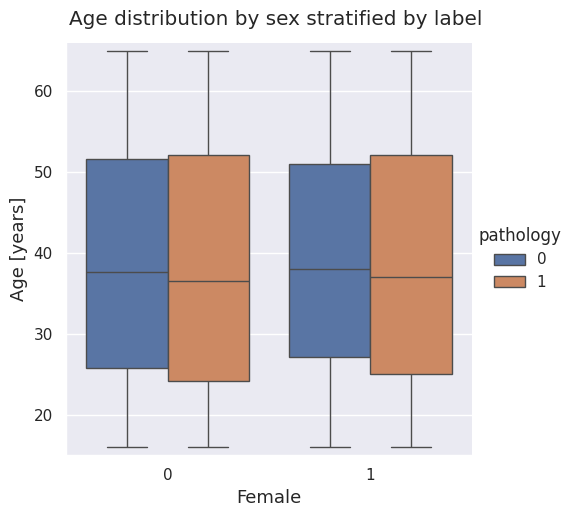

In [19]:
g = sns.catplot(
    x="female",
    y="age",
    data=df,
    hue="pathology",
    kind="box"
)

g.figure.suptitle(t = "Age distribution by sex stratified by label", y = 1.03)
g.set(
    xlabel="Female",
    ylabel="Age [years]",
    ylim=(15, 66)
)

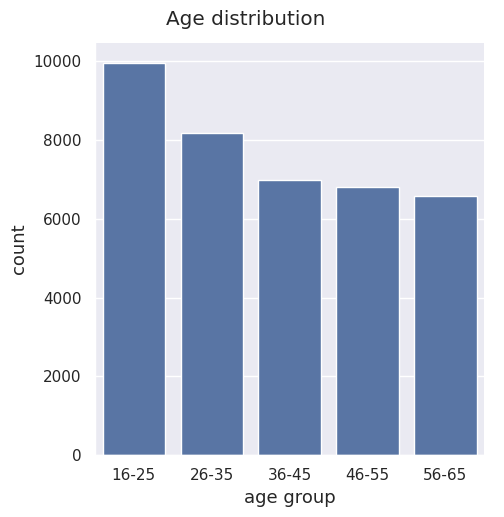

In [20]:
# age distribution (in bins of 10 years)
g = sns.catplot(x='age_group',
                data = df,
                kind = 'count',
                order=AGE_ORDER)

g.figure.suptitle('Age distribution', y = 1.03)
g.set(xlabel = 'age group')


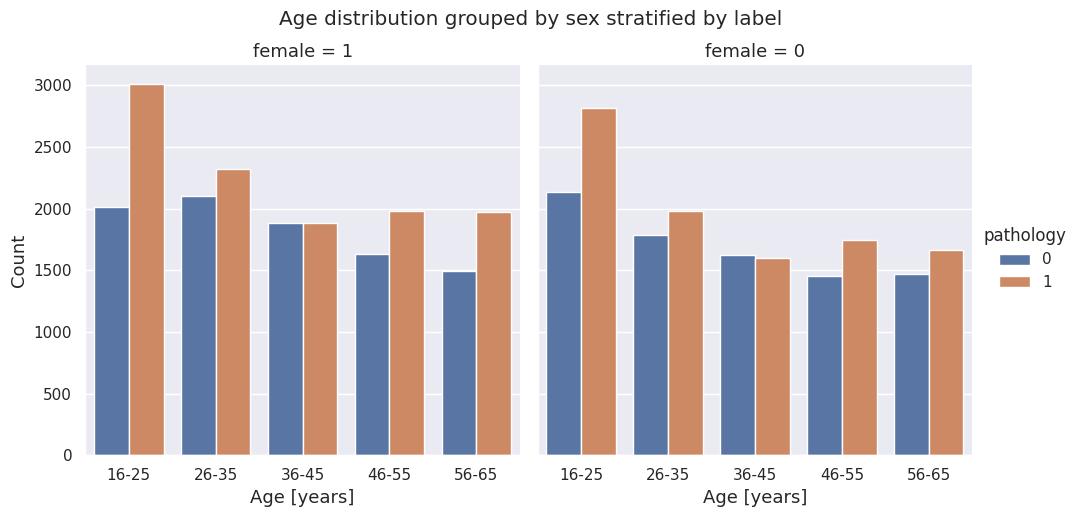

In [21]:
g = sns.catplot(x='age_group',
                data = df,
                hue = 'pathology',
                kind = 'count',
                col = "female",
                order = AGE_ORDER,
                col_order= [1,0])

g.figure.suptitle('Age distribution grouped by sex stratified by label', y = 1.03)
g.set(xlabel = 'Age [years]', ylabel = 'Count')

/tmp/ipykernel_2011697/2804642777.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(x='pathology',


Text(0.5, 1.03, 'Label distribution per sex')

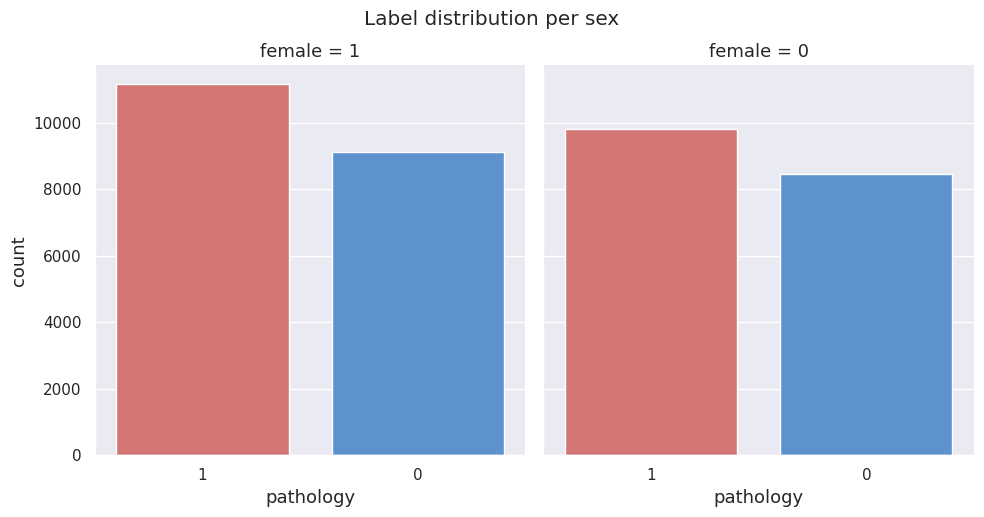

In [22]:
g = sns.catplot(x='pathology', 
            data = df,
            kind = 'count',
            order = [1, 0],
            col = "female",
            col_order = [1,0],
            palette = LABEL_PALETTE)

g.figure.suptitle('Label distribution per sex', y = 1.03)

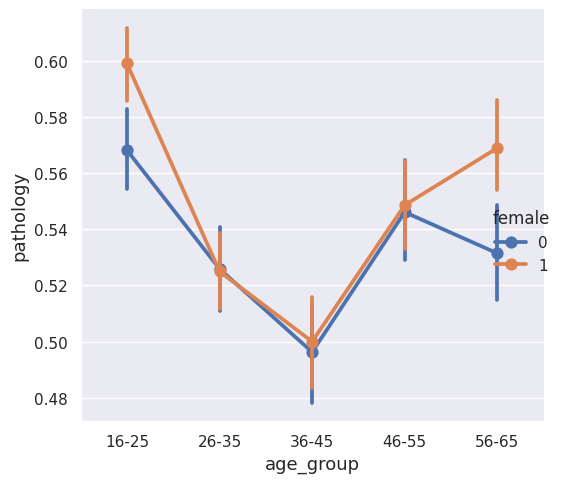

In [23]:
sns.catplot(x = "age_group",
            y = "pathology",
            data = df,
            kind = "point",
            hue = "female",
            order = AGE_ORDER,
            legend_out=True)

plt.tight_layout()

## per site

In [24]:
sites_data = pd.DataFrame({
    'site': SITE_ORDER,
    '#exams': df['site'].value_counts().loc[SITE_ORDER].values,
    '#unique_subs': df.groupby('site')['patient_id'].nunique().loc[SITE_ORDER].values,
    '#unique_long_subs': df.groupby('site')['patient_id'].value_counts().gt(1).groupby('site').sum().loc[SITE_ORDER].values})

sites_data.style.hide(axis='index')

site,#exams,#unique_subs,#unique_long_subs
S00,1915,1657,169
S01,4376,3682,499
S02,3057,2462,350
S03,3010,1568,177
S04,1493,1147,181
S05,1859,1474,249
S06,2873,2196,415
S07,2559,2469,55
S08,2044,1495,324
S09,1972,1916,52


In [25]:
temp_df = pd.merge(df, sites_data, on=['site'], how='inner')
longitudinal_data = (
    temp_df
    .groupby(['site', 'patient_id'])
    .size()
    .loc[lambda x: x > 1]
    .reset_index(name='n_exams')
)

In [26]:
longitudinal_data

,site,patient_id,n_exams
0,S00,P00009,4
1,S00,P00046,3
2,S00,P02422,2
3,S00,P02462,2
4,S00,P02810,3
...,...,...,...
3707,S29,P22790,2
3708,S29,P29277,2
3709,S29,P29283,2
3710,S29,P29284,2


In [27]:
N_longs = len(longitudinal_data["site"].unique())

In [28]:
print("Number of sites with longitudinal patients:", N_longs)
print("The only site without longitudinal patients is:", set(df['site'].unique()) - set(longitudinal_data["site"].unique()))

Number of sites with longitudinal patients: 27
The only site without longitudinal patients is: {'S20', 'S27', 'S15'}


In [29]:
sites_data.to_csv(new_filename_1, index=False)
longitudinal_data.to_csv(new_filename_2, index=False)

print(f"Saved site metadata to: {new_filename_1}")
print(f"Saved longitudinal patients metadata to: {new_filename_2}")

Saved site metadata to: /dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/data/meta/sites_processed.csv
Saved longitudinal patients metadata to: /dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/data/meta/longitudinal_processed.csv
